# MF 731 Homework 3, Part 2 - VaR backtesting on the S&P 500

Code only. Write-up and discussion are in `hw3_part2_written.ipynb`.

Sheet 2 of Homework 3: backtesting one-day VaR for $1 in the S&P 500,
Q1 to Q4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

ALPHA = 0.95
LAM = 0.97          # EWMA mean
THETA = 0.97        # EWMA variance
M = 1010            # rolling window, in returns

plt.rcParams['figure.figsize'] = (11, 5)

### Q1. Data

In [2]:
# Daily S&P 500 closes (^GSPC), saved to csv. To pull fresh data instead:
#     yf.download('^GSPC', start='2016-05-23', end='2026-05-23')['Close']
sp = pd.read_csv('sp500_daily.csv', parse_dates=['Date']).set_index('Date')['Close']
print('first five observations'); print(sp.head())
print('\nlast five observations'); print(sp.tail())
N_SP = len(sp)
print('\nN =', N_SP, 'observations,', sp.index[0].date(), '->', sp.index[-1].date())

xs = np.log(sp / sp.shift(1)).dropna()
xv = xs.values
J = len(xv) - M
print('log returns:', len(xv), '   window M =', M, '   evaluation periods J =', J)

first five observations
Date
2016-05-23    2048.040039
2016-05-24    2076.060059
2016-05-25    2090.540039
2016-05-26    2090.100098
2016-05-27    2099.060059
Name: Close, dtype: float64

last five observations
Date
2026-05-18    7403.049805
2026-05-19    7353.609863
2026-05-20    7432.970215
2026-05-21    7445.720215
2026-05-22    7473.470215
Name: Close, dtype: float64

N = 2515 observations, 2016-05-23 -> 2026-05-22
log returns: 2514    window M = 1010    evaluation periods J = 1504


### Q2. Historical simulation on a rolling 1010-day window

The $1 loss operator is derived by hand (attached).

In [3]:
def loss_sp(x):
    # full loss operator for a constant $1 position
    return -(np.exp(x) - 1)

realized = loss_sp(xv[M:])                  # L_{s+Delta} for the J evaluation days
eval_dates = xs.index[M:]

var_h = np.empty(J)
k = int(np.ceil(M * ALPHA))
for j in range(J):
    window = xv[j:j + M]                    # the M returns up to and including day s
    var_h[j] = np.sort(loss_sp(window))[k - 1]
exc_h = realized > var_h
print('order statistic k = ceil(M*alpha) =', k)
print('historical simulation: exceedances = %d of %d  (%.2f%%)' % (exc_h.sum(), J, 100 * exc_h.mean()))

order statistic k = ceil(M*alpha) = 960
historical simulation: exceedances = 55 of 1504  (3.66%)


### Q3. Normal log returns with EWMA updating

The VaR formula under normal returns is derived by hand (attached).

In [4]:
mu_e = xv[:M].mean()                        # initial estimates from the first 1010 returns
s2_e = xv[:M].var(ddof=1)
print('initial  mu = %.4e   sigma = %.4e' % (mu_e, np.sqrt(s2_e)))

var_e = np.empty(J)
sd_path = np.empty(J)
z = norm.ppf(1 - ALPHA)
for j in range(J):
    var_e[j] = 1 - np.exp(mu_e + np.sqrt(s2_e) * z)      # forecast for the coming day
    sd_path[j] = np.sqrt(s2_e)
    x_new = xv[M + j]                                     # then observe the day and update
    s2_e = THETA * s2_e + (1 - THETA) * (x_new - mu_e)**2
    mu_e = LAM * mu_e + (1 - LAM) * x_new
exc_e = realized > var_e
print('final    mu = %.4e   sigma = %.4e' % (mu_e, np.sqrt(s2_e)))
print('normal + EWMA: exceedances = %d of %d  (%.2f%%)' % (exc_e.sum(), J, 100 * exc_e.mean()))

initial  mu = 3.8771e-04   sigma = 1.2413e-02
final    mu = 1.7689e-03   sigma = 8.4225e-03
normal + EWMA: exceedances = 94 of 1504  (6.25%)


### Q4. Confidence interval for the number of exceedances

The binomial distribution of the count and the interval are derived by hand
(attached); evaluated here.

In [5]:
BETA = 0.05
expected = J * (1 - ALPHA)
sd_n = np.sqrt(J * ALPHA * (1 - ALPHA))
zb = norm.ppf(1 - BETA / 2)
lo, hi = expected - zb * sd_n, expected + zb * sd_n
print('J = %d   E[N] = %.2f   sd = %.3f   z = %.4f' % (J, expected, sd_n, zb))
print('normal-approximation %.0f%% CI: (%.2f, %.2f)' % (100 * (1 - BETA), lo, hi))
print('exact binomial %.0f%% CI:        (%d, %d)' % (100 * (1 - BETA), binom.ppf(BETA / 2, J, 1 - ALPHA),
                                                      binom.ppf(1 - BETA / 2, J, 1 - ALPHA)))
for name, e in [('historical simulation', exc_h), ('normal + EWMA', exc_e)]:
    inside = lo <= e.sum() <= hi
    print('%-22s N_hat = %3d   %s' % (name, e.sum(), 'inside -> do not reject' if inside else 'OUTSIDE -> reject'))

J = 1504   E[N] = 75.20   sd = 8.452   z = 1.9600
normal-approximation 95% CI: (58.63, 91.77)
exact binomial 95% CI:        (59, 92)
historical simulation  N_hat =  55   OUTSIDE -> reject
normal + EWMA          N_hat =  94   OUTSIDE -> reject


In [6]:
# yearly breakdown of exceedances, to see where they cluster
yr = pd.DataFrame({'historical': exc_h.astype(int), 'ewma': exc_e.astype(int)}, index=eval_dates)
by_year = yr.groupby(yr.index.year).sum()
by_year['days'] = yr.groupby(yr.index.year).size()
print(by_year.T)
print('\nmean VaR level: historical %.4f   ewma %.4f' % (var_h.mean(), var_e.mean()))
print('days both exceed: %d   historical only: %d   ewma only: %d'
      % ((exc_h & exc_e).sum(), (exc_h & ~exc_e).sum(), (~exc_h & exc_e).sum()))

Date        2020  2021  2022  2023  2024  2025  2026
historical     8     6    20     0     7    11     3
ewma           7    12    19    13    18    15    10
days         151   252   251   250   252   250    98

mean VaR level: historical 0.0188   ewma 0.0162
days both exceed: 47   historical only: 8   ewma only: 47


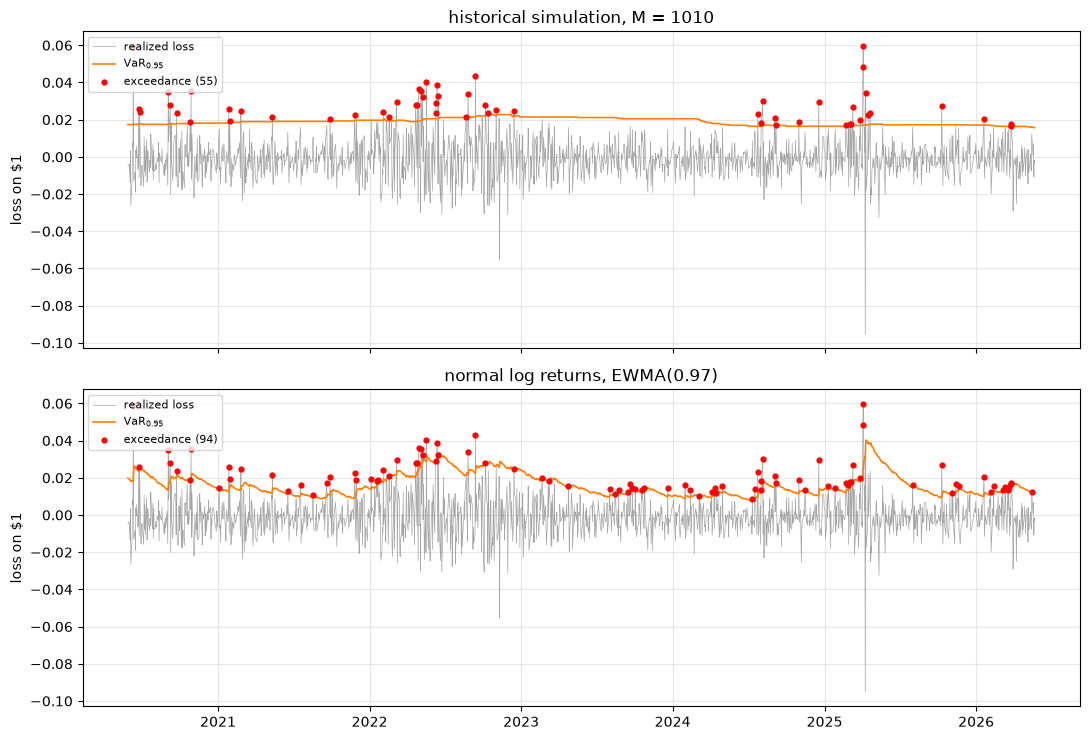

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for a, v, e, name in [(ax[0], var_h, exc_h, 'historical simulation, M = 1010'),
                      (ax[1], var_e, exc_e, 'normal log returns, EWMA(0.97)')]:
    a.plot(eval_dates, realized, color='grey', lw=0.5, alpha=0.7, label='realized loss')
    a.plot(eval_dates, v, color='C1', lw=1.2, label=r'VaR$_{0.95}$')
    a.scatter(eval_dates[e], realized[e], color='red', s=12, zorder=3, label='exceedance (%d)' % e.sum())
    a.set_title(name)
    a.set_ylabel('loss on $1')
    a.legend(loc='upper left', fontsize=8)
    a.grid(alpha=0.3)
fig.tight_layout()
plt.show()